# TEP diagnostics — sub-pilot003 / ses-prime / run 103

Focused diagnostic notebook, companion to `PRIME_online_performance.ipynb`. Three parts:

**Part A.** Sensor-space TEPs for the intervention blocks' single-pulse trials — `prime_single_pulse`
and `predetermined_single` (the `prime_triplet` condition is excluded here; a 100 Hz triplet
response isn't a single-pulse TEP) — read directly from the buffers `2_intervention.py` already
preprocessed and saved online (`*_post_proc.npy`). Nothing is recomputed in this part.

**Part B.** Sensor-space TEPs for `baseline` and the four `evaluation` blocks, which only ever saved
*raw* buffers online — reprocessed here through the session's own saved calibration state
(`calibration_bunble.npy`) and the actual `prime_core.preprocessing.Preprocessor`, the same
offline-replay approach `PRIME_online_performance.ipynb` chapter 2 uses.

**Part C.** One question drives this notebook's existence: baseline/evaluation TEPs show an
unnatural, sharp jump in amplitude at almost exactly **+38 ms** — clearly not a physiological
component onset. Part C traces this to a specific mechanism inside `preprocess_post` and confirms
it empirically against this session's own data, rather than describing it in general terms.

Sensor space only throughout — no dipole fitting here (see `PRIME_online_performance.ipynb` for
that). This notebook only *reads* from `prime/`; nothing in `prime/` is modified.

## 1 · Setup

In [2]:
from __future__ import annotations

import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (10, 3.4),
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

COLOR_PREDETERMINED = "#5b8ff9"   # blue
COLOR_PRIME_SINGLE   = "#e8684a"  # orange
COLOR_PRIME_TRIPLET  = "#9270ca"  # purple (unused -- triplets excluded -- kept for palette consistency)
JUMP_MS = 38   # the latency under investigation in Part C; marked on every waveform plot below

print(f"numpy {np.__version__}  pandas {pd.__version__}  mne {mne.__version__}")

numpy 2.3.2  pandas 2.3.1  mne 1.10.0


In [3]:
SUBJECT_ID = "pilot003"     # BIDS subject label, without the "sub-" prefix
SESSION_ID = "ses-prime"    # BIDS session label
RUN_ID     = "103"          # NeuroSimo run folder

def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError(
        "Could not locate the Loop root (a folder containing both 'BIDS' and 'prime'). "
        "Set the LOOP_ROOT environment variable, or edit _find_loop_root()."
    )

LOOP_ROOT = _find_loop_root()
SUBJECT_DIR = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID / RUN_ID / "prime"
if not SUBJECT_DIR.is_dir():
    raise FileNotFoundError(f"Session folder not found: {SUBJECT_DIR}")

print(f"Loop root : {LOOP_ROOT}")
print(f"session   : sub-{SUBJECT_ID} / {SESSION_ID} / run {RUN_ID}")
print(f"data dir  : {SUBJECT_DIR}")

Loop root : D:\Linus\Loop
session   : sub-pilot003 / ses-prime / run 103
data dir  : D:\Linus\Loop\BIDS\sub-pilot003\ses-prime\103\prime


## 2 · Restore the session's calibrated state

Same restoration `PRIME_online_performance.ipynb` chapter 2 uses: `Preprocessor.from_bundle()` on
the session's own saved `calibration_bunble.npy`, so every trial below is processed with the exact
filters, ICA, SOUND matrix and SSP-SIR kernel this session actually calibrated and used online —
nothing here is refit. No `DipoleFitter` / forward solution is used for fitting — this notebook
stays in sensor space throughout.

In [4]:
sys.path.insert(0, str(LOOP_ROOT / "prime" / "decider"))
from prime_core.preprocessing.preprocessor import Preprocessor
import prime_core.preprocessing.preprocessor as pp_mod
from prime_core.prime_config import (
    get_raw_sfreq, get_qc_time_range, get_post_initial_time_range,
    get_post_time_range, epoch_n_times, get_processed_sfreq,
)

fwd_path = LOOP_ROOT / "prime" / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
calibration_bundle = np.load(SUBJECT_DIR / "calibration_bunble.npy", allow_pickle=True).item()
proc_info = np.load(SUBJECT_DIR / "proc_info.npy", allow_pickle=True).item()

preprocessor = Preprocessor.from_bundle(calibration_bundle, fwd_path)
preprocessor.keep_full_epochs = True   # populates last_post_full, used throughout below

bad_channels = list(calibration_bundle["bad_channels"])
interp = calibration_bundle["channel_interpolation_info"]
ch_names = list(preprocessor._info["ch_names"])
assert ch_names == list(proc_info["ch_names"]), \
    "channel order mismatch between the restored Preprocessor and proc_info.npy"

RAW_SFREQ = get_raw_sfreq()
QC_TMIN, QC_TMAX = get_qc_time_range()
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()
POST_TMIN, POST_TMAX = get_post_time_range()
n_post_times = epoch_n_times(POST_TMIN, POST_TMAX, get_processed_sfreq())
post_time_ms = np.linspace(POST_TMIN * 1000, POST_TMAX * 1000, n_post_times)

dipole_epoch_tmin_ms = proc_info["dipole"]["tmin"] * 1000
dipole_epoch_tmax_ms = proc_info["dipole"]["tmax"] * 1000

GFP = lambda evoked: evoked.std(axis=0, ddof=0)   # used throughout parts A-C

print(f"{len(ch_names)} channels; bad_channels ({len(bad_channels)}): {', '.join(bad_channels)}")
print(f"post-stimulus epoch: [{POST_TMIN*1000:.0f}, {POST_TMAX*1000:.0f}] ms, {n_post_times} samples "
      f"({get_processed_sfreq():.0f} Hz)")
print(f"N45/dipole window (this project's own operational definition): "
      f"[{dipole_epoch_tmin_ms:.0f}, {dipole_epoch_tmax_ms:.0f}] ms")

60 channels; bad_channels (5): C3, CP3, FC1, P4, T7
post-stimulus epoch: [1, 100] ms, 100 samples (1000 Hz)
N45/dipole window (this project's own operational definition): [38, 50] ms


## Part A · Intervention — sensor-space TEPs from the ONLINE-preprocessed buffers

`2_intervention.py` calls `preprocessor.preprocess_post()` **in real time** during the intervention
blocks (that result is what feeds `TEPNormalizer` / PRIME's trigger decision) and saves its output
as `<stem>_post_proc.npy` — a `(60, 100)` array over the same `[1, 100]` ms window used everywhere
else in this notebook. Nothing is recomputed in this part; these are exactly the arrays the online
system itself produced.

**Trial selection.** `trials_intervention.csv`'s `stage` column is `intervention_block_<1-4>` and
`trial_in_stage` is `0..199`, which together give the file stem
(`intervention_block_<N>_<trial_in_stage:04d>`) directly — confirmed against the files on disk, not
assumed. Per the request, only `condition in {prime_single_pulse, predetermined_single}` is used
here (`prime_triplet`, 480/800 trials, is excluded — a 100 Hz triplet response is a different object
from a single-pulse TEP). Trials are further restricted to `postprocessing_failed == False`:
134/800 intervention trials (17%) are flagged online as failing post-stimulus processing (mostly
the ocular-ICA check inside `preprocess_post`) but — checked explicitly below — still have a
`_post_proc.npy` file saved with plausible-looking, non-NaN values, so this can't be inferred from
file existence and has to be filtered on directly.

(`_pre_proc.npy`, also saved per trial, is a different pipeline: `preprocessor.preprocess_pre()`, a
`(60, 201)` **pre-stimulus** QC/model-input window used for PRIME's real-time trigger decision,
never passed through SOUND or SSP-SIR. It is not a post-stimulus TEP and is not used for waveform
plotting below.)

In [5]:
trials_intervention = pd.read_csv(SUBJECT_DIR / "trials_intervention.csv")
interv = trials_intervention[
    trials_intervention["stage"].str.startswith("intervention_block", na=False)
].copy()
interv["trial_in_stage"] = interv["trial_in_stage"].astype(int)
interv["stem"] = interv["stage"] + "_" + interv["trial_in_stage"].map(lambda i: f"{i:04d}")

print(f"{len(interv)} intervention trials total")
print(interv["condition"].value_counts())
print(f"\npreprocessing_failed (pre-stim buffer):  {int(interv['preprocessing_failed'].sum())}/{len(interv)}")
print(f"postprocessing_failed (post-stim buffer): {int(interv['postprocessing_failed'].sum())}/{len(interv)}")

# spot-check: does a postprocessing_failed trial still have a plausible (non-NaN, non-zero) saved buffer?
_ex = interv[interv["postprocessing_failed"] == True].iloc[0]
_arr = np.load(SUBJECT_DIR / f"{_ex['stem']}_post_proc.npy")
print(f"\nexample postprocessing_failed=True trial ({_ex['stem']}): file exists, shape {_arr.shape}, "
      f"nan frac {np.isnan(_arr).mean():.2f}, |max| {np.nanmax(np.abs(_arr)):.1f} "
      f"-- saved regardless of the flag, so the flag must be applied as a filter, not inferred from the file.")

800 intervention trials total
condition
prime_triplet           480
prime_single_pulse      240
predetermined_single     80
Name: count, dtype: int64

preprocessing_failed (pre-stim buffer):  7/800
postprocessing_failed (post-stim buffer): 134/800

example postprocessing_failed=True trial (intervention_block_1_0007): file exists, shape (60, 100), nan frac 0.00, |max| 1292.8 -- saved regardless of the flag, so the flag must be applied as a filter, not inferred from the file.


In [6]:
CONDITIONS = ["prime_single_pulse", "predetermined_single"]
intervention_traces = {c: [] for c in CONDITIONS}
intervention_counts = {c: {"total": 0, "postproc_failed": 0, "file_missing": 0, "used": 0} for c in CONDITIONS}

for cond in CONDITIONS:
    rows = interv[interv["condition"] == cond]
    intervention_counts[cond]["total"] = len(rows)
    for _, row in rows.iterrows():
        if row["postprocessing_failed"]:
            intervention_counts[cond]["postproc_failed"] += 1
            continue
        fp = SUBJECT_DIR / f"{row['stem']}_post_proc.npy"
        if not fp.is_file():
            intervention_counts[cond]["file_missing"] += 1
            continue
        intervention_traces[cond].append(np.load(fp))
        intervention_counts[cond]["used"] += 1

print("trial counts by condition:")
display(pd.DataFrame(intervention_counts).T)

evoked_intervention = {c: np.mean(np.stack(v, axis=0), axis=0)
                        for c, v in intervention_traces.items() if v}

trial counts by condition:


,total,postproc_failed,file_missing,used
prime_single_pulse,240,37,0,203
predetermined_single,80,10,0,70


### Part A plots — a few channels, then a full butterfly plot per condition

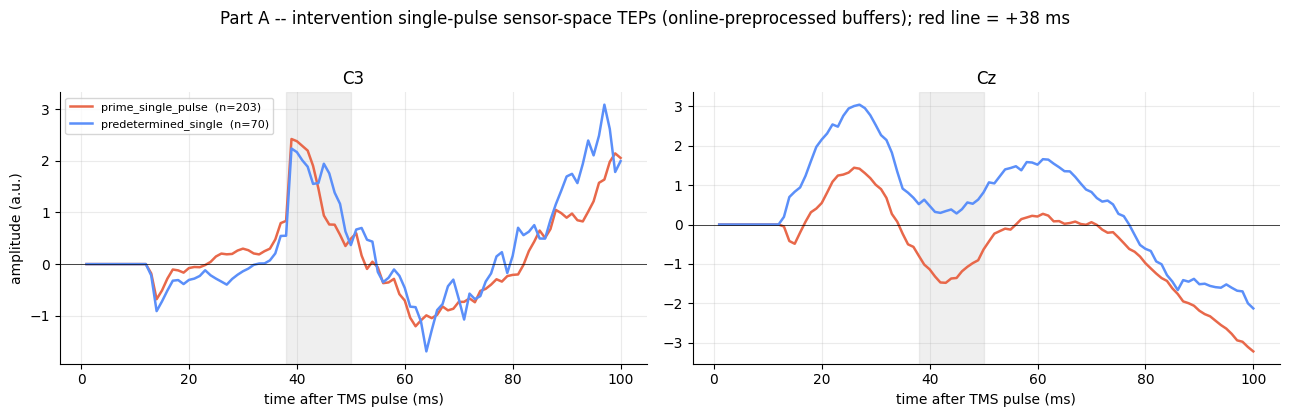

In [7]:
PLOT_CHANNELS = [c for c in ["C3", "Cz"] if c in ch_names]
for ch in PLOT_CHANNELS:
    if ch in bad_channels:
        print(f"WARNING: {ch} is in this session's bad_channels -- its trace below is "
              f"reconstructed from neighbouring channels (interpolated), not measured.")

fig, axes = plt.subplots(1, len(PLOT_CHANNELS), figsize=(6.5 * len(PLOT_CHANNELS), 4), squeeze=False)
axes = axes[0]
cond_colors = {"prime_single_pulse": COLOR_PRIME_SINGLE, "predetermined_single": COLOR_PREDETERMINED}
for ax, ch in zip(axes, PLOT_CHANNELS):
    idx = ch_names.index(ch)
    for cond in CONDITIONS:
        if cond not in evoked_intervention:
            continue
        ax.plot(post_time_ms, evoked_intervention[cond][idx], lw=1.8, color=cond_colors[cond],
                 label=f"{cond}  (n={intervention_counts[cond]['used']})")
    ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(ch)
    ax.set_xlabel("time after TMS pulse (ms)")
axes[0].set_ylabel("amplitude (a.u.)")
axes[0].legend(fontsize=8)
fig.suptitle("Part A -- intervention single-pulse sensor-space TEPs (online-preprocessed buffers); "
             f"red line = +{JUMP_MS} ms", y=1.03)
fig.tight_layout()
plt.show()

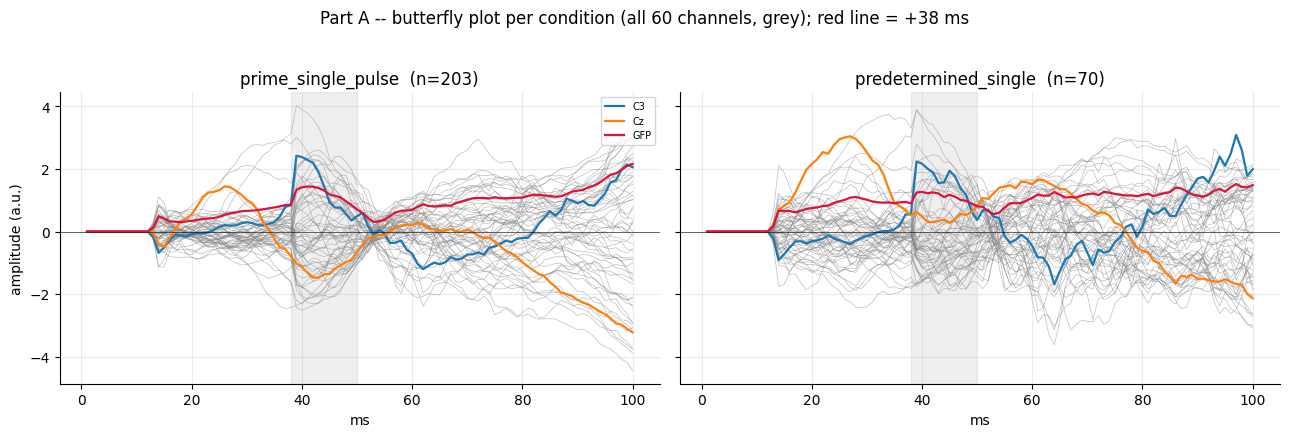

In [20]:
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(6.5 * len(CONDITIONS), 4.2), sharey=True)
for ax, cond in zip(axes, CONDITIONS):
    if cond not in evoked_intervention:
        ax.set_visible(False)
        continue
    evoked = evoked_intervention[cond]
    ax.plot(post_time_ms, evoked.T, lw=0.5, color="grey", alpha=0.5)
    for ch in PLOT_CHANNELS:
        idx = ch_names.index(ch)
        ax.plot(post_time_ms, evoked[idx], lw=1.6, label=ch)
    ax.plot(post_time_ms, GFP(evoked), lw=1.6, color="crimson", label="GFP")
    ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
    ax.axhline(0, color="black", lw=0.4)
    ax.set_title(f"{cond}  (n={intervention_counts[cond]['used']})")
    ax.set_xlabel("ms")
axes[0].set_ylabel("amplitude (a.u.)")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle(f"Part A -- butterfly plot per condition (all 60 channels, grey); red line = +{JUMP_MS} ms", y=1.03)
fig.tight_layout()
plt.show()

## Part B · Baseline & Evaluation — reprocessed exactly as online

`1_baseline.py` and `3_evaluation.py` only save each trial's raw pre-/post-stimulus buffers —
online, they never call `preprocess_post` at all (see their module docstrings). This part runs that
deferred computation here, through the `preprocessor` restored in Section 2 — the same approach
`PRIME_online_performance.ipynb` chapter 2 uses.

The four evaluation runs are numbered by creation order, not explicitly labelled t0/t15/t30/t60 in
the data; the mapping used below (`evaluation_1..4` → `t0/t15/t30/t60`) is inferred from both the
`trials_evaluation_<N>.csv` write timestamps and the raw buffer file timestamps on disk (both
increase strictly in that order, ~15-30 minutes apart, consistent with the protocol's
t0/t15/t30/t60 spacing after intervention) — see `claude/PRIME_online_performance_notes.md`.

The monkeypatch installed below also captures `ssp_sir_single_trial`'s input/output for every
trial that reaches it — needed for Part C — so this loop only has to run once.

In [9]:
BLOCKS = [
    ("baseline",   None, "baseline"),
    ("evaluation", 1,    "evaluation_t0"),
    ("evaluation", 2,    "evaluation_t15"),
    ("evaluation", 3,    "evaluation_t30"),
    ("evaluation", 4,    "evaluation_t60"),
]
BLOCK_LABELS = [label for _, _, label in BLOCKS]

def _stem(stage, run, trial):
    prefix = stage if run is None else f"{stage}_{run}"
    return f"{prefix}_{trial:04d}"

def _n_trials(stage, run):
    prefix = stage if run is None else f"{stage}_{run}"
    return len(sorted(SUBJECT_DIR.glob(f"{prefix}_*_pre_raw.npy")))

# ---- monkeypatch ssp_sir_single_trial (as imported into the preprocessor module) so Part C can
# ---- see exactly what SSP-SIR changes on this session's real data, without a second pass.
_orig_ssp_sir = pp_mod.ssp_sir_single_trial
ssp_sir_io = {label: {"pre": [], "post": []} for label in BLOCK_LABELS}
_current_block = {"label": None}

def _spy(trial_data, P, sir_projmat_suppr, sir_projmat_orig, filter_kernel):
    out = _orig_ssp_sir(trial_data, P, sir_projmat_suppr, sir_projmat_orig, filter_kernel)
    label = _current_block["label"]
    if label is not None:
        ssp_sir_io[label]["pre"].append(trial_data.copy())
        ssp_sir_io[label]["post"].append(out.copy())
    return out

pp_mod.ssp_sir_single_trial = _spy
print("ssp_sir_single_trial monkeypatched (spy) -- restored to the original after the loop below.")

ssp_sir_single_trial monkeypatched (spy) -- restored to the original after the loop below.


In [10]:
records = []
sensor_traces = {label: [] for _, _, label in BLOCKS}

for stage, run, label in BLOCKS:
    _current_block["label"] = label
    for trial in range(_n_trials(stage, run)):
        stem = _stem(stage, run, trial)
        pre_raw = np.load(SUBJECT_DIR / f"{stem}_pre_raw.npy")
        post_raw = np.load(SUBJECT_DIR / f"{stem}_post_raw.npy")
        pre_ts = QC_TMIN + np.arange(pre_raw.shape[0]) / RAW_SFREQ
        post_ts = POST_I_TMIN + np.arange(post_raw.shape[0]) / RAW_SFREQ

        preprocessor.preprocess_pre(pre_raw, pre_ts, from_pulse=True)
        post = preprocessor.preprocess_post(post_raw, post_ts)

        records.append({
            "block": label, "trial": trial,
            "postprocessing_success": post is not None,
            "postprocessing_reject_reason": preprocessor.last_post_reject_reason,
        })
        if post is not None:
            sensor_traces[label].append(preprocessor.last_post_full)

_current_block["label"] = None
pp_mod.ssp_sir_single_trial = _orig_ssp_sir   # restore -- Part C reads the captured lists, not live calls

replay = pd.DataFrame.from_records(records)
summary = replay.groupby("block", sort=False).agg(
    n_trials=("trial", "size"),
    postprocessing_failures=("postprocessing_success", lambda s: int((~s).sum())),
).reindex(BLOCK_LABELS)
display(summary)

evoked_by_block = {b: np.mean(np.stack(sensor_traces[b], axis=0), axis=0)
                    for b in BLOCK_LABELS if sensor_traces[b]}
gfp_by_block = {b: GFP(evoked_by_block[b]) for b in evoked_by_block}

print("\nhow far into the pipeline each block's trials get (n_trials attempted / postprocessing "
      "succeeded / reached ssp_sir_single_trial) -- shown as data, not assumed:")
display(pd.DataFrame({
    "n_trials": {b: _n_trials(*next((s, r) for s, r, l in BLOCKS if l == b)) for b in BLOCK_LABELS},
    "postprocessing_success": {b: len(sensor_traces[b]) for b in BLOCK_LABELS},
    "reached_ssp_sir": {b: len(ssp_sir_io[b]["pre"]) for b in BLOCK_LABELS},
}))

,n_trials,postprocessing_failures
block,,
baseline,100,5
evaluation_t0,100,8
evaluation_t15,100,10
evaluation_t30,100,4
evaluation_t60,100,10



how far into the pipeline each block's trials get (n_trials attempted / postprocessing succeeded / reached ssp_sir_single_trial) -- shown as data, not assumed:


,n_trials,postprocessing_success,reached_ssp_sir
baseline,100,95,100
evaluation_t0,100,92,100
evaluation_t15,100,90,100
evaluation_t30,100,96,100
evaluation_t60,100,90,100


### Part B plots

GFP first (polarity-blind, the standard scalp-ERP summary), then the signed waveform at a
representative channel (so N45's negative sign is visible), a donor-channel check if that channel
is interpolated, and a full butterfly plot — the same structure as chapter 2's item 4, reproduced
here so this notebook is self-contained.

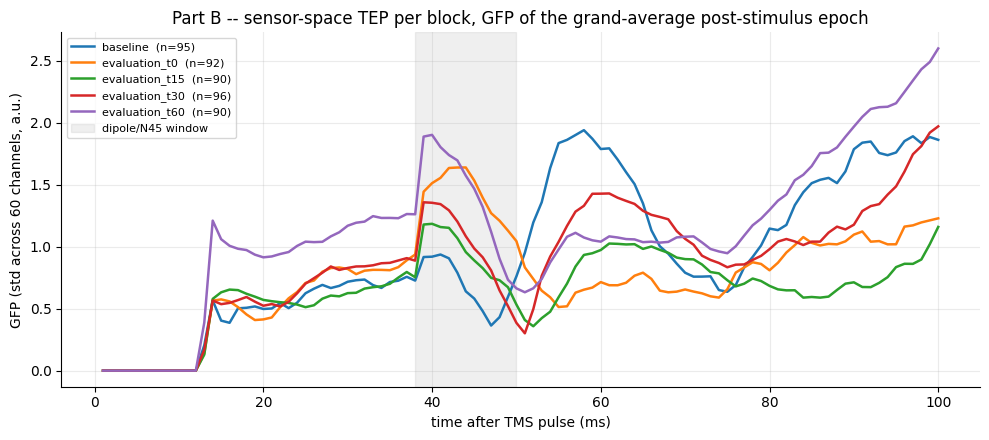

baseline         GFP peak = 1.9403  at 58 ms
evaluation_t0    GFP peak = 1.6392  at 44 ms
evaluation_t15   GFP peak = 1.1847  at 40 ms
evaluation_t30   GFP peak = 1.9712  at 100 ms
evaluation_t60   GFP peak = 2.5998  at 100 ms


In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for b in BLOCK_LABELS:
    if b not in gfp_by_block:
        continue
    ax.plot(post_time_ms, gfp_by_block[b], lw=1.8, label=f"{b}  (n={len(sensor_traces[b])})")
ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12, label="dipole/N45 window")
ax.set_xlabel("time after TMS pulse (ms)")
ax.set_ylabel("GFP (std across 60 channels, a.u.)")
ax.set_title("Part B -- sensor-space TEP per block, GFP of the grand-average post-stimulus epoch")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for b in BLOCK_LABELS:
    if b in gfp_by_block:
        peak_i = int(np.argmax(gfp_by_block[b]))
        print(f"{b:16s} GFP peak = {gfp_by_block[b][peak_i]:.4f}  at {post_time_ms[peak_i]:.0f} ms")

representative channel: C3



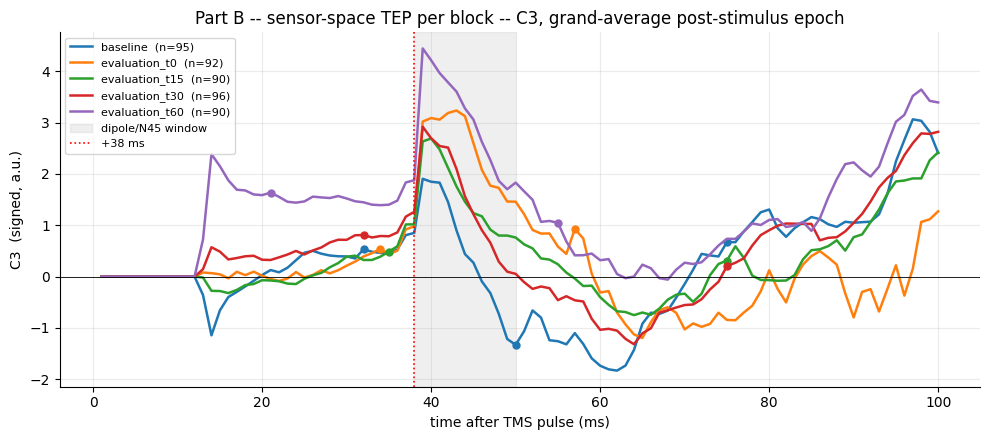

,P30_latency_ms,P30_amplitude,N45_latency_ms,N45_amplitude,P60_latency_ms,P60_amplitude
block,,,,,,
baseline,32.0,0.530876,50.0,-1.329506,75.0,0.672368
evaluation_t0,34.0,0.543876,NaN,NaN,57.0,0.929740
evaluation_t15,35.0,0.487718,NaN,NaN,75.0,0.313861
evaluation_t30,32.0,0.810421,NaN,NaN,75.0,0.204222
evaluation_t60,21.0,1.635825,NaN,NaN,55.0,1.048320


In [12]:
COMPONENT_WINDOWS = {
    "P30": (20.0, 35.0, "max"),
    "N45": (dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, "min"),
    "P60": (55.0, 75.0, "max"),
}

CH = "C3"
if CH in ch_names:
    ch_idx = ch_names.index(CH)
else:
    lo, hi, _ = COMPONENT_WINDOWS["N45"]
    win = (post_time_ms >= lo) & (post_time_ms <= hi)
    base = evoked_by_block.get("baseline", next(iter(evoked_by_block.values())))
    ch_idx = int(np.argmax(np.abs(base[:, win]).max(axis=1)))
    CH = f"{ch_names[ch_idx]} (fallback -- C3 not in this montage)"

resolved_ch_name = ch_names[ch_idx]
print(f"representative channel: {CH}")
if resolved_ch_name in bad_channels:
    print(
        f"WARNING: {resolved_ch_name} is in this session's bad_channels "
        f"({', '.join(bad_channels)}), interpolated at calibration -- every trace below at this "
        f"channel is reconstructed from neighbouring good channels (channel_interpolation_info), "
        f"not measured EEG."
    )
print()

def _local_extremum(trace_1d, lo_ms, hi_ms, kind):
    win_idx = np.where((post_time_ms >= lo_ms) & (post_time_ms <= hi_ms))[0]
    seg = trace_1d[win_idx]
    i = win_idx[int(np.argmax(seg) if kind == "max" else np.argmin(seg))]
    lat, amp = post_time_ms[i], trace_1d[i]
    if (kind == "max" and amp < 0) or (kind == "min" and amp > 0):
        return np.nan, np.nan
    return lat, amp

fig, ax = plt.subplots(figsize=(10, 4.5))
peak_records = []
for b in BLOCK_LABELS:
    if b not in evoked_by_block:
        continue
    trace = evoked_by_block[b][ch_idx]
    line, = ax.plot(post_time_ms, trace, lw=1.8, label=f"{b}  (n={len(sensor_traces[b])})")
    row = {"block": b}
    for comp, (lo, hi, kind) in COMPONENT_WINDOWS.items():
        lat, amp = _local_extremum(trace, lo, hi, kind)
        if not np.isnan(amp):
            ax.plot(lat, amp, marker="o", ms=5, color=line.get_color())
        row[f"{comp}_latency_ms"], row[f"{comp}_amplitude"] = lat, amp
    peak_records.append(row)

ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12, label="dipole/N45 window")
ax.axvline(JUMP_MS, color="red", ls=":", lw=1.2, label=f"+{JUMP_MS} ms")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("time after TMS pulse (ms)")
ax.set_ylabel(f"{CH}  (signed, a.u.)")
ax.set_title(f"Part B -- sensor-space TEP per block -- {CH}, grand-average post-stimulus epoch")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

peak_df = pd.DataFrame.from_records(peak_records).set_index("block").reindex(BLOCK_LABELS)
display(peak_df)

#### Is `C3`'s shape real, or an interpolation artifact?

C3's top 5 interpolation donors (by |weight|): FC3 (+0.38), C1 (+0.37), C5 (+0.29), CP1 (+0.21), CP5 (+0.18)


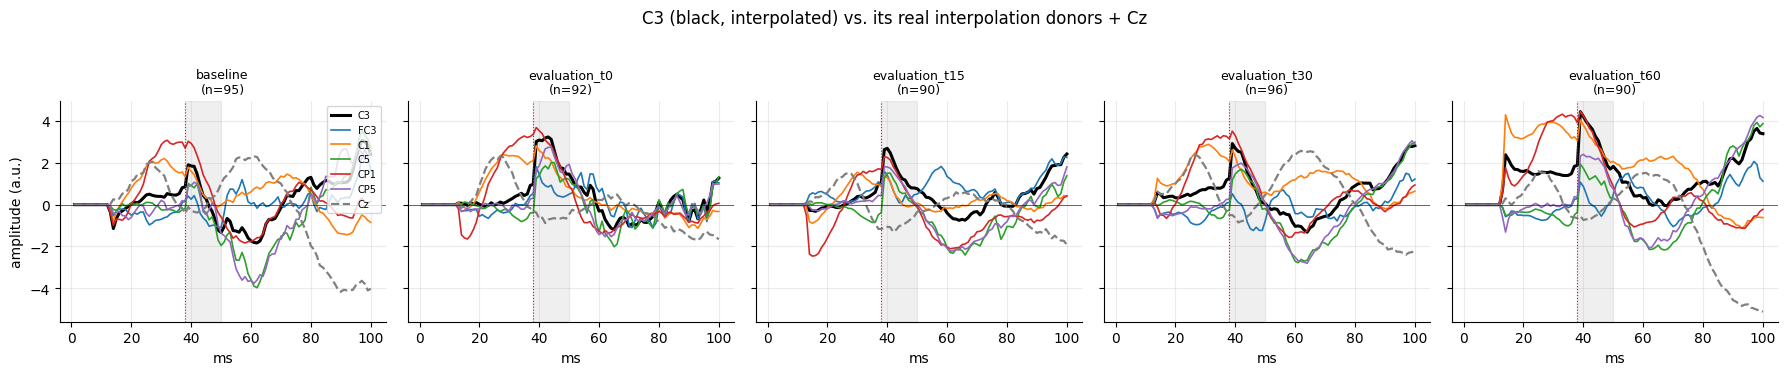

In [13]:
N_DONORS = 5

if resolved_ch_name in bad_channels:
    bads_idx, goods_idx = interp["bads_idx"], interp["goods_idx"]
    bad_order = [ch_names[i] for i in range(len(ch_names)) if bads_idx[i]]
    good_order = [ch_names[i] for i in range(len(ch_names)) if goods_idx[i]]
    row_i = bad_order.index(resolved_ch_name)
    weights = interp["interpolation_matrix"][row_i]
    top_i = np.argsort(-np.abs(weights))[:N_DONORS]
    donors = [good_order[i] for i in top_i]
    print(f"{resolved_ch_name}'s top {N_DONORS} interpolation donors (by |weight|): " +
          ", ".join(f"{good_order[i]} ({weights[i]:+.2f})" for i in top_i))

    ref_ch = "Cz" if ("Cz" in ch_names and "Cz" != resolved_ch_name and "Cz" not in donors) else None
    plot_chs = [resolved_ch_name] + donors + ([ref_ch] if ref_ch else [])
    donor_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    fig, axes = plt.subplots(1, len(BLOCK_LABELS), figsize=(3.6 * len(BLOCK_LABELS), 3.6),
                              sharey=True, sharex=True)
    for ax, b in zip(axes, BLOCK_LABELS):
        if b not in evoked_by_block:
            ax.set_visible(False)
            continue
        di = 0
        for ch in plot_chs:
            idx = ch_names.index(ch)
            if ch == resolved_ch_name:
                color, lw, ls = "black", 2.2, "-"
            elif ch == ref_ch:
                color, lw, ls = "grey", 1.6, "--"
            else:
                color, lw, ls = donor_colors[di % len(donor_colors)], 1.2, "-"
                di += 1
            ax.plot(post_time_ms, evoked_by_block[b][idx], lw=lw, ls=ls, color=color, label=ch)
        ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
        ax.axvline(JUMP_MS, color="red", ls=":", lw=0.8)
        ax.axhline(0, color="black", lw=0.4)
        ax.set_title(f"{b}\n(n={len(sensor_traces[b])})", fontsize=9)
        ax.set_xlabel("ms")
    axes[0].set_ylabel("amplitude (a.u.)")
    axes[0].legend(fontsize=7, loc="upper right")
    fig.suptitle(f"{resolved_ch_name} (black, interpolated) vs. its real interpolation donors"
                 + (f" + {ref_ch}" if ref_ch else ""), y=1.03)
    fig.tight_layout()
    plt.show()
else:
    print(f"{resolved_ch_name} is not an interpolated channel in this session -- no donor comparison to show.")

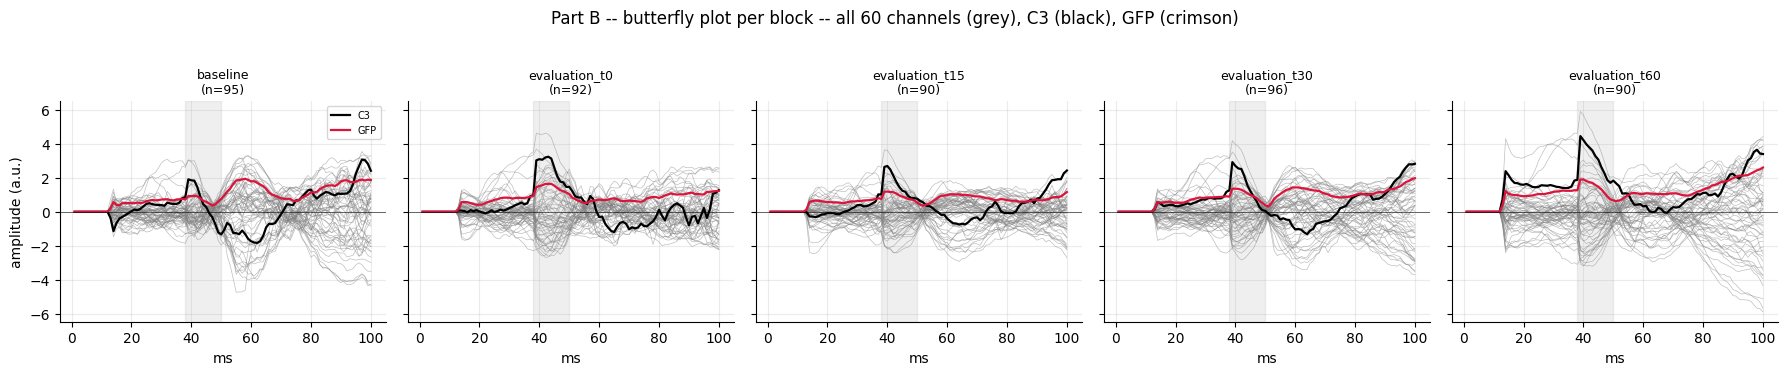

In [23]:
fig, axes = plt.subplots(1, len(BLOCK_LABELS), figsize=(3.6 * len(BLOCK_LABELS), 3.6),
                          sharey=True, sharex=True)
for ax, b in zip(axes, BLOCK_LABELS):
    if b not in evoked_by_block:
        ax.set_visible(False)
        continue
    evoked = evoked_by_block[b]
    ax.plot(post_time_ms, evoked.T, lw=0.5, color="grey", alpha=0.5)
    ax.plot(post_time_ms, evoked[ch_idx], lw=1.6, color="black", label=CH.split(" ")[0])
    ax.plot(post_time_ms, gfp_by_block[b], lw=1.6, color="crimson", label="GFP")
    ax.axvspan(dipole_epoch_tmin_ms, dipole_epoch_tmax_ms, color="grey", alpha=0.12)
    ax.axhline(0, color="black", lw=0.4)
    ax.set_title(f"{b}\n(n={len(sensor_traces[b])})", fontsize=9)
    ax.set_xlabel("ms")
axes[0].set_ylabel("amplitude (a.u.)")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Part B -- butterfly plot per block -- all 60 channels (grey), "
             f"{CH.split(' ')[0]} (black), GFP (crimson)", y=1.03)
fig.tight_layout()
plt.show()

## Part C · What produces the +38 ms jump

Ruling out the spatial/non-temporal steps first, since none of them can explain a **new** feature
appearing at one specific latency and not its neighbours:

- **The two stim-artifact interpolation windows** (`fix_stim_artifact`,
  `prime_core/preprocessing/config.py`) sit at roughly `[-14, 14]` ms and `[1, 15]` ms — nowhere
  near 38 ms, and their edges show up as flat segments early in every trace above, not a spike at
  38 ms. Confirmed against the live config below rather than assumed.
- **SOUND** (`prime_core/preprocessing/utils/sound_modified.py`) is a purely spatial
  `(n_channels, n_channels)` matrix, applied identically at every timepoint of the epoch (confirmed
  below) — it can reshape the scalp topography, but it structurally cannot manufacture a new
  temporal feature at one latency and not others.

That leaves **SSP-SIR** (`ssp_sir_single_trial`, `prime_core/preprocessing/utils/ssp_sir_python.py`),
the last spatial-filtering step before the second stim-artifact fix. Unlike SOUND, SSP-SIR blends
two *different* spatial reconstructions of the trial using a temporal weighting profile
(`filter_kernel`) that is not flat across the epoch — so if that profile itself has a sharp corner,
the blend inherits it.

In [15]:
sound_filter = calibration_bundle["sound_filter"]
print(f"sound_filter shape: {sound_filter.shape}  -- a single (n_channels, n_channels) matrix, no time axis.")
print(f"applied in preprocess_post as  data = sound_filter @ data  -- the same matrix at every one of "
      f"the {n_post_times} timepoints in the epoch, so it cannot introduce a discontinuity at one "
      f"latency and not others.")

aw1 = preprocessor._cfg.artifact_window_1
aw2 = preprocessor._cfg.artifact_window_2
print(f"\nartifact_window_1 (1st stim-artifact interpolation): [{aw1[0]*1000:.0f}, {aw1[1]*1000:.0f}] ms")
print(f"artifact_window_2 (2nd stim-artifact interpolation): [{POST_TMIN*1000:.0f}, {aw2[1]*1000:.0f}] ms")
print(f"both well before {JUMP_MS} ms.")

sound_filter shape: (60, 60)  -- a single (n_channels, n_channels) matrix, no time axis.
applied in preprocess_post as  data = sound_filter @ data  -- the same matrix at every one of the 100 timepoints in the epoch, so it cannot introduce a discontinuity at one latency and not others.

artifact_window_1 (1st stim-artifact interpolation): [-14, 14] ms
artifact_window_2 (2nd stim-artifact interpolation): [1, 15] ms
both well before 38 ms.


sspsir_filter_kernel shape: (60, 100)  (n_channels, n_samples)
identical across all 60 channels: True
computed ONCE at calibration (preprocess_calibration -> ssp_sir_to_average on the calibration grand average) and reused UNCHANGED by ssp_sir_single_trial for every trial this session, online and in Part B's replay above alike.


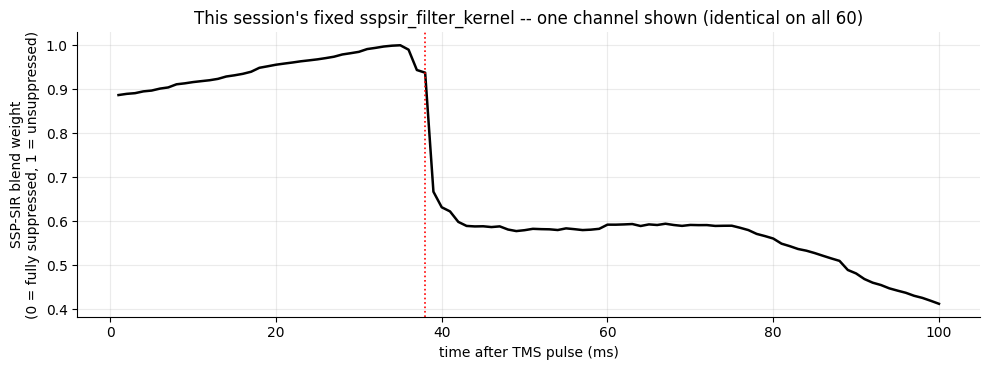


steepest single-sample change anywhere in the kernel's 100 samples: t=38 -> 39 ms, delta=-0.2705  (kernel 0.9377 -> 0.6672)
next steepest step anywhere else in the epoch: 0.0462
-> the 38-39 ms step is 5.9x steeper than anywhere else in the kernel.


In [16]:
kernel = calibration_bundle["sspsir_filter_kernel"]
assert kernel.shape[1] == len(post_time_ms)
print(f"sspsir_filter_kernel shape: {kernel.shape}  (n_channels, n_samples)")
print(f"identical across all {kernel.shape[0]} channels: {np.allclose(kernel, kernel[0:1, :])}")
print("computed ONCE at calibration (preprocess_calibration -> ssp_sir_to_average on the calibration "
      "grand average) and reused UNCHANGED by ssp_sir_single_trial for every trial this session, "
      "online and in Part B's replay above alike.")

kernel_1d = kernel[0]
d_kernel = np.diff(kernel_1d)
i_steep = int(np.argmax(np.abs(d_kernel)))
other_steps = np.delete(np.abs(d_kernel), i_steep)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(post_time_ms, kernel_1d, lw=1.8, color="black")
ax.axvline(JUMP_MS, color="red", ls=":", lw=1.2)
ax.set_xlabel("time after TMS pulse (ms)")
ax.set_ylabel("SSP-SIR blend weight\n(0 = fully suppressed, 1 = unsuppressed)")
ax.set_title("This session's fixed sspsir_filter_kernel -- one channel shown (identical on all 60)")
fig.tight_layout()
plt.show()

print(f"\nsteepest single-sample change anywhere in the kernel's {kernel.shape[1]} samples: "
      f"t={post_time_ms[i_steep]:.0f} -> {post_time_ms[i_steep+1]:.0f} ms, "
      f"delta={d_kernel[i_steep]:+.4f}  (kernel {kernel_1d[i_steep]:.4f} -> {kernel_1d[i_steep+1]:.4f})")
print(f"next steepest step anywhere else in the epoch: {other_steps.max():.4f}")
print(f"-> the {post_time_ms[i_steep]:.0f}-{post_time_ms[i_steep+1]:.0f} ms step is "
      f"{np.abs(d_kernel[i_steep]) / other_steps.max():.1f}x steeper than anywhere else in the kernel.")

### Why a kernel discontinuity looks like an amplitude jump

`ssp_sir_single_trial` (see `get_data_corrected` in `ssp_sir_python.py`) computes two different
spatial reconstructions of the same trial — `orig_data_sir` (a leadfield-informed reconstruction of
the data essentially as recorded) and `suppr_data_sir` (the same, after an SVD-based spatial filter
`P` has suppressed the components SSP-SIR identified as artifact) — and blends them **per
timepoint**:

    data_corrected(t) = orig_data_sir(t) + kernel(t) * (suppr_data_sir(t) - orig_data_sir(t))

`kernel(t)` is the profile plotted above: near 1 (mostly `orig`) through the early, artifact-heavy
part of the epoch, falling toward 0 (mostly `suppr`) later on. Where the kernel changes smoothly,
the blend changes smoothly. Where it doesn't — the step quantified above — the output abruptly
changes *how much of each reconstruction it's showing*, independent of what the underlying neural
signal is doing at that instant. Because `orig_data_sir` and `suppr_data_sir` are literally
different spatial projections of the data (not scaled copies of one another), even a trial with a
perfectly smooth true TEP would show a kink here.

Because this kernel is fixed once at calibration and reused unchanged for every trial for the rest
of the session, **whatever latency its envelope estimate happens to have its sharpest corner at,
every trial processed this session inherits a synthetic jump there.** For sub-pilot003/ses-prime/103
that latency is 38-39 ms; there is nothing anatomically or physiologically special about "38 ms"
here — it is a property of this one session's calibration data, not the protocol.

### Empirical check: does SSP-SIR itself introduce the jump, in this session's real data?

The kernel's shape says SSP-SIR *could* produce a jump at 38-39 ms. To check it actually does,
using the Part B monkeypatch's captured input/output of every trial that reached
`ssp_sir_single_trial`: for each block, compare the grand-average **input** (post-SOUND,
pre-SSP-SIR) against the grand-average **output** (post-SSP-SIR), with a measure that doesn't
depend on picking one channel or latency by eye -- for each of the 60 channels, find the single
latency where *that channel's own trace* changes fastest anywhere across the whole 1-100 ms epoch,
then count how many channels land on 38->39 ms specifically. If channels' steepest moments were
scattered at random across the 99 possible 1 ms steps, chance alone predicts about 60/99 ~= 0.6
channels landing on any one specific step.

In [17]:
i38 = int(np.where(np.round(post_time_ms) == JUMP_MS)[0][0])

def steepest_at_jump_count(arr_2d):
    d = np.diff(arr_2d, axis=1)
    k = np.argmax(np.abs(d), axis=1)
    return int(np.sum(k == i38))

rows = []
for b in BLOCK_LABELS:
    if not ssp_sir_io[b]["pre"]:
        continue
    pre_avg = np.mean(np.stack(ssp_sir_io[b]["pre"], axis=0), axis=0)
    post_avg = np.mean(np.stack(ssp_sir_io[b]["post"], axis=0), axis=0)
    rows.append({
        "block": b, "n_trials": len(ssp_sir_io[b]["pre"]),
        "pre_SSPSIR": steepest_at_jump_count(pre_avg),
        "post_SSPSIR": steepest_at_jump_count(post_avg),
        "final": steepest_at_jump_count(evoked_by_block[b]),
    })

concentration = pd.DataFrame(rows).set_index("block")
chance = 60 / 99
print(f"# of 60 channels whose SINGLE steepest 1ms transition anywhere in [1,100]ms lands at "
      f"{JUMP_MS}->{JUMP_MS+1}ms  (chance level ~= {chance:.2f} per block):\n")
display(concentration)
print(f"\nsummed across all {len(concentration)} blocks ({60*len(concentration)} channel-block pairs, "
      f"chance level {chance*len(concentration):.1f}):")
print(f"  pre-SSPSIR : {concentration['pre_SSPSIR'].sum()}")
print(f"  post-SSPSIR: {concentration['post_SSPSIR'].sum()}")
print(f"  final      : {concentration['final'].sum()}")

# of 60 channels whose SINGLE steepest 1ms transition anywhere in [1,100]ms lands at 38->39ms  (chance level ~= 0.61 per block):



,n_trials,pre_SSPSIR,post_SSPSIR,final
block,,,,
baseline,100,1,11,8
evaluation_t0,100,1,34,34
evaluation_t15,100,0,37,38
evaluation_t30,100,0,32,34
evaluation_t60,100,0,29,34



summed across all 5 blocks (300 channel-block pairs, chance level 3.0):
  pre-SSPSIR : 2
  post-SSPSIR: 143
  final      : 148


In [18]:
print(f"same check on Part A's intervention buffers (`_post_proc.npy`, already the ONLINE result -- "
      f"no pre-SSPSIR intermediate saved online, so 'final' only):\n")
for cond in CONDITIONS:
    if cond not in evoked_intervention:
        continue
    n_final = steepest_at_jump_count(evoked_intervention[cond])
    print(f"  {cond:24s} (n={intervention_counts[cond]['used']:3d} trials): "
          f"{n_final}/60 channels' steepest 1ms step lands at {JUMP_MS}-{JUMP_MS+1}ms  (chance ~0.6)")

same check on Part A's intervention buffers (`_post_proc.npy`, already the ONLINE result -- no pre-SSPSIR intermediate saved online, so 'final' only):

  prime_single_pulse       (n=203 trials): 37/60 channels' steepest 1ms step lands at 38-39ms  (chance ~0.6)
  predetermined_single     (n= 70 trials): 22/60 channels' steepest 1ms step lands at 38-39ms  (chance ~0.6)


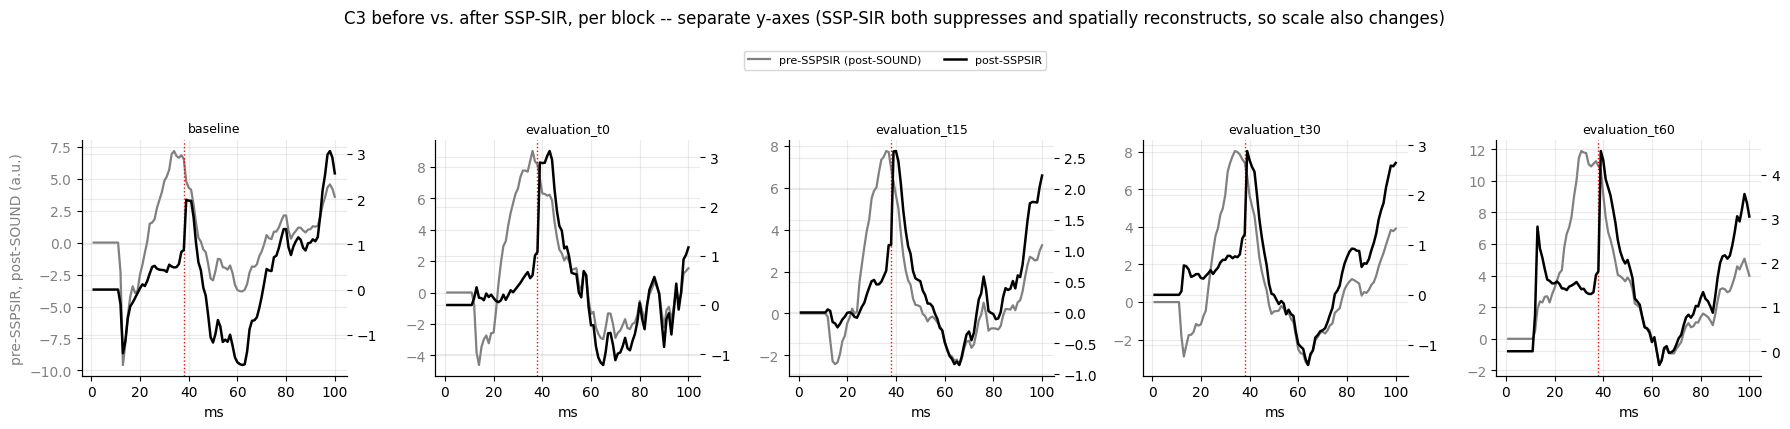

In [19]:
fig, axes = plt.subplots(1, len(BLOCK_LABELS), figsize=(3.6 * len(BLOCK_LABELS), 3.6), sharex=True)
C3_idx = ch_names.index("C3") if "C3" in ch_names else 0
for ax, b in zip(axes, BLOCK_LABELS):
    if not ssp_sir_io[b]["pre"]:
        ax.set_visible(False)
        continue
    pre_avg = np.mean(np.stack(ssp_sir_io[b]["pre"], axis=0), axis=0)
    post_avg = np.mean(np.stack(ssp_sir_io[b]["post"], axis=0), axis=0)
    ax2 = ax.twinx()
    l1, = ax.plot(post_time_ms, pre_avg[C3_idx], color="grey", lw=1.6)
    l2, = ax2.plot(post_time_ms, post_avg[C3_idx], color="black", lw=1.8)
    ax.axvline(JUMP_MS, color="red", ls=":", lw=1.0)
    ax.set_title(f"{b}", fontsize=9)
    ax.set_xlabel("ms")
    ax.tick_params(axis="y", labelcolor="grey")
    ax2.tick_params(axis="y", labelcolor="black")
axes[0].set_ylabel("pre-SSPSIR, post-SOUND (a.u.)", color="grey")
fig.legend([l1, l2], ["pre-SSPSIR (post-SOUND)", "post-SSPSIR"], loc="upper center", ncol=2,
           fontsize=8, bbox_to_anchor=(0.5, 1.08))
fig.suptitle(f"{ch_names[C3_idx]} before vs. after SSP-SIR, per block -- separate y-axes "
             f"(SSP-SIR both suppresses and spatially reconstructs, so scale also changes)", y=1.18)
fig.tight_layout()
plt.show()

### Connection to the donor-channel finding in `PRIME_online_performance.ipynb`

Chapter 2 of the companion notebook found that `C3`'s `[38, 50]` ms window is dominated by a sharp
*positive* deflection in every evaluation block (baseline shows a small negative candidate N45
there instead), and confirmed with a donor-channel comparison that this positive deflection is
**not an interpolation artifact** — `C1`, `C5`, `CP1` and `CP5` (`C3`'s real, non-interpolated top
interpolation donors) share the same shape, so it isn't manufactured by reconstructing `C3` from
its neighbours.

That finding rules out *one* artifact mechanism (bad-channel interpolation) but not this one.
`sspsir_filter_kernel` is identical across **every** channel (confirmed above), so a jump it
introduces would appear at the same latency and a similar shape on `C3`, its donors, and every
other channel simultaneously — exactly the pattern a shared-topography check like the donor
comparison cannot distinguish from genuine shared neural signal. The onset of that positive
deflection (~38 ms) lining up with the kernel's steepest transition is at minimum consistent with
it being wholly or partly this processing artifact rather than a physiological response — this
notebook's data cannot fully separate the two, since both predict a broadly-shared, sharp change
starting around 38 ms. What this does establish is a second, better-supported candidate mechanism
for what chapter 2 explicitly left as an open question, on top of ruling out bad-channel
interpolation as the explanation.

## Summary

- The +38 ms jump traces to a specific, identifiable mechanism: `sspsir_filter_kernel` — computed
  once at calibration from this session's own data and reused unchanged for every trial — has its
  single steepest 1 ms transition in the entire 100 ms epoch at 38->39 ms (Part C). Because
  `preprocess_post`'s SSP-SIR step blends two differently-reconstructed versions of the signal using
  this kernel as a per-timepoint weight, that transition imprints a synthetic amplitude jump at that
  exact latency, on top of whatever the true neural signal is doing.
- This is empirically confirmed, not just plausible: across baseline and all four evaluation blocks,
  the number of channels whose single steepest moment in the whole epoch falls at 38-39 ms jumps
  from roughly chance level before SSP-SIR to well above chance after it (Part C).
- The same fixed kernel processes intervention trials online, and Part A's `prime_single_pulse` /
  `predetermined_single` grand averages show the same above-chance concentration at 38-39 ms in
  their final, online-computed result — so this is not specific to the offline replay in Part B, and
  not specific to one condition.
- SOUND and both stim-artifact interpolation windows are ruled out as the cause (Part C): SOUND is
  structurally time-invariant, and the interpolation windows sit at 14-15 ms, not 38 ms.
- This also gives a second, better-supported candidate explanation for the sharp positive deflection
  chapter 2 of `PRIME_online_performance.ipynb` found (and left open) at `C3` in the evaluation
  blocks — its ~38 ms onset lines up with this mechanism.
- **Not resolved here:** *why* this session's calibration data produced a kernel with its sharpest
  corner specifically at 38-39 ms (a property of `ssp_sir_to_average`'s automatic envelope estimate
  on this subject's calibration trials, not investigated further), and whether other
  sessions/subjects show the same artifact at a different, session-specific latency -- checking
  either would mean loading other sessions' calibration bundles, which this notebook does not do.
  No fix is attempted either -- one would mean changing how the calibration-time kernel is computed
  or smoothed in `prime_core/preprocessing`, out of scope for a read-only diagnostic notebook.